In [1]:
from pathlib import Path

DATA_DIR = Path("data/ROCOv2")

print("Dataset location:", DATA_DIR.resolve())
print("Directory exists:", DATA_DIR.exists())

for file in sorted(DATA_DIR.iterdir()):
    print(f"{file.name:35} {file.stat().st_size / (1024**2):.2f} MB")

Dataset location: C:\Users\zakar\OneDrive\Bureau\AI4VIS\data\ROCOv2
Directory exists: True
cui_mapping (1).csv                 0.06 MB
license_information.csv             9.01 MB
test_captions.csv                   1.69 MB
test_concepts.csv                   0.53 MB
test_concepts_manual.csv            0.36 MB
test_images.zip                     818.02 MB
train_captions.csv                  9.63 MB
train_concepts.csv                  3.21 MB
train_concepts_manual.csv           2.24 MB
train_images.zip                    4397.81 MB
valid_captions.csv                  1.69 MB
valid_concepts.csv                  0.53 MB
valid_concepts_manual.csv           0.37 MB
valid_images.zip                    820.53 MB


In [4]:
import pandas as pd

splits = ["train", "valid", "test"]

captions = {}
manual_concepts = {}

for split in splits:

    captions_path = DATA_DIR / f"{split}_captions.csv"
    concepts_path = DATA_DIR / f"{split}_concepts_manual.csv"

    if captions_path.exists():
        captions[split] = pd.read_csv(captions_path)

        print(f"\n{split.upper()} CAPTIONS")
        print("Shape:", captions[split].shape)
        display(captions[split].head(3))

    if concepts_path.exists():
        manual_concepts[split] = pd.read_csv(concepts_path)

        print(f"\n{split.upper()} MANUAL CONCEPTS")
        print("Shape:", manual_concepts[split].shape)
        display(manual_concepts[split].head(3))


TRAIN CAPTIONS
Shape: (59958, 2)


,ID,Caption
0,ROCOv2_2023_train_000001,Head CT demonstrating left parotiditis.
1,ROCOv2_2023_train_000002,Acquired renal cysts in end-stage renal failur...
2,ROCOv2_2023_train_000003,Computed tomography of the chest showing the r...



TRAIN MANUAL CONCEPTS
Shape: (59958, 2)


,ID,CUIs
0,ROCOv2_2023_train_000001,C0040405
1,ROCOv2_2023_train_000002,C0041618
2,ROCOv2_2023_train_000003,C0040405



VALID CAPTIONS
Shape: (9904, 2)


,ID,Caption
0,ROCOv2_2023_valid_000001,Chest X-ray showing enlarged cardiac silhouett...
1,ROCOv2_2023_valid_000002,Digital subtraction ureterogram with contrast ...
2,ROCOv2_2023_valid_000003,Fifty-eight-year-old woman with 2 cancers: one...


... (2 outputs left out)


TEST CAPTIONS
Shape: (9927, 2)


,ID,Caption
0,ROCOv2_2023_test_000001,CT chest axial view showing a huge ascending a...
1,ROCOv2_2023_test_000002,Computed tomography (CT) shows floating thromb...
2,ROCOv2_2023_test_000003,Digitally subtracted angiogram demonstrates ac...



TEST MANUAL CONCEPTS
Shape: (9927, 2)


,ID,CUIs
0,ROCOv2_2023_test_000001,C0040405
1,ROCOv2_2023_test_000002,C0040405
2,ROCOv2_2023_test_000003,C0002978


In [6]:
cui_mapping = pd.read_csv(DATA_DIR / "cui_mapping (1).csv")

print("Mapping shape:", cui_mapping.shape)
print("Columns:", cui_mapping.columns.tolist())

display(cui_mapping.head(10))

Mapping shape: (1934, 2)
Columns: ['CUI', 'Canonical name']


,CUI,Canonical name
0,C0016522,"Foramen Ovale, Patent"
1,C0457846,Cervical segment of spinal cord
2,C0578537,Cavitation of lung
3,C0179751,Epidural catheter
4,C3489393,Hiatal Hernia
5,C0730166,Bone structure of fifth metacarpal
6,C1261077,Structure of left lower lobe of lung
7,C0152443,Urethral diverticulum
8,C0227301,Descending part of duodenum
9,C0031354,Pharyngeal structure


Images in test archive: 9927


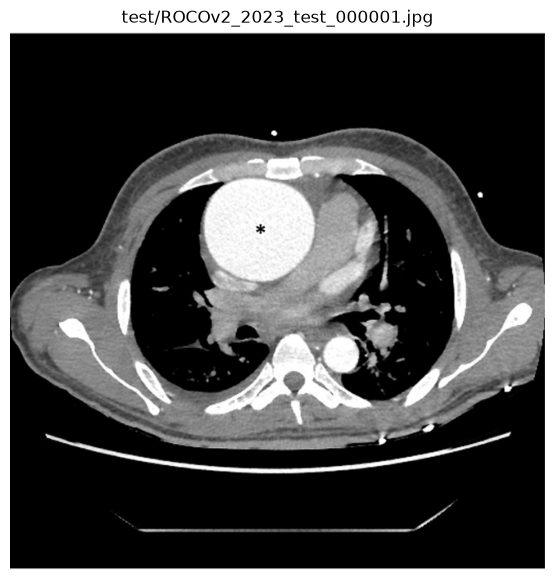

In [7]:
import zipfile
from PIL import Image
import matplotlib.pyplot as plt

test_zip = DATA_DIR / "test_images.zip"

with zipfile.ZipFile(test_zip, "r") as archive:

    image_files = [
        name for name in archive.namelist()
        if name.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    print("Images in test archive:", len(image_files))

    image_name = image_files[0]

    with archive.open(image_name) as image_file:
        image = Image.open(image_file).convert("RGB")

    plt.figure(figsize=(7, 7))
    plt.imshow(image)
    plt.title(image_name)
    plt.axis("off")
    plt.show()

In [8]:
cui_to_name = dict(
    zip(
        cui_mapping["CUI"],
        cui_mapping["Canonical name"]
    )
)

print(cui_to_name.get("C0040405"))
print(cui_to_name.get("C0041618"))
print(cui_to_name.get("C0002978"))

X-Ray Computed Tomography
Ultrasonography
angiogram


In [9]:
def decode_cuis(cui_string):

    if pd.isna(cui_string):
        return []

    codes = str(cui_string).split(";")

    return [
        cui_to_name.get(code.strip(), "Unknown CUI")
        for code in codes
    ]

In [10]:
test_data = captions["test"].merge(
    manual_concepts["test"],
    on="ID",
    how="inner",
    validate="one_to_one"
)

test_data["Concept names"] = (
    test_data["CUIs"].apply(decode_cuis)
)

display(
    test_data[["ID", "Caption", "CUIs", "Concept names"]].head(10)
)

,ID,Caption,CUIs,Concept names
0,ROCOv2_2023_test_000001,CT chest axial view showing a huge ascending a...,C0040405,[X-Ray Computed Tomography]
1,ROCOv2_2023_test_000002,Computed tomography (CT) shows floating thromb...,C0040405,[X-Ray Computed Tomography]
2,ROCOv2_2023_test_000003,Digitally subtracted angiogram demonstrates ac...,C0002978,[angiogram]
3,ROCOv2_2023_test_000004,Digitally subtracted angiogram of the IMA demo...,C0002978,[angiogram]
4,ROCOv2_2023_test_000005,Angle measurement of a Type 1 canal.,C0040405,[X-Ray Computed Tomography]
5,ROCOv2_2023_test_000006,Computed tomography on day 26Follow-up enhance...,C0040405,[X-Ray Computed Tomography]
6,ROCOv2_2023_test_000007,Enhanced CT scan of the chest revealed an ante...,C0040405,[X-Ray Computed Tomography]
7,ROCOv2_2023_test_000008,Arrow shows ULP at the distal arch.,C0040405,[X-Ray Computed Tomography]
8,ROCOv2_2023_test_000009,Early sagittal T2-weighted MRI.,C0024485,[Magnetic Resonance Imaging]
9,ROCOv2_2023_test_000010,Late axial T2-weighted MRI.,C0024485,[Magnetic Resonance Imaging]


In [11]:
keywords = (
    r"computed tomography|"
    r"magnetic resonance|"
    r"ultrason|"
    r"angiogram|"
    r"angiography|"
    r"positron emission|"
    r"plain x-ray|"
    r"radiography|"
    r"pet/ct"
)

modality_candidates = cui_mapping[
    cui_mapping["Canonical name"].str.contains(
        keywords,
        case=False,
        na=False,
        regex=True
    )
]

display(modality_candidates)

,CUI,Canonical name
204,C3472245,Single Photon Emission Computed Tomography Com...
484,C0024485,Magnetic Resonance Imaging
517,C0412650,Computed tomography of cervical spine
617,C0002978,angiogram
776,C0040405,X-Ray Computed Tomography
804,C0041618,Ultrasonography
1091,C0243032,Magnetic Resonance Angiography
1132,C1306645,Plain x-ray
1320,C0729619,Computed tomography imaging - action
1702,C1699633,PET/CT scan


In [12]:
from collections import Counter

all_cuis = Counter()

for split in splits:
    for cui_string in manual_concepts[split]["CUIs"].dropna():

        codes = str(cui_string).split(";")

        for code in codes:
            all_cuis[code.strip()] += 1

print("Unique CUIs:", len(all_cuis))

for cui, count in all_cuis.most_common(20):
    print(
        cui,
        cui_to_name.get(cui, "Unknown"),
        count
    )

Unique CUIs: 18
C0040405 X-Ray Computed Tomography 27747
C1306645 Plain x-ray 21997
C0024485 Magnetic Resonance Imaging 12657
C0041618 Ultrasonography 11429
C1999039 Anterior-Posterior 9605
C0817096 Chest 7388
C0002978 angiogram 4799
C1996865 Postero-Anterior 4303
C0037303 Bone structure of cranium 3973
C0023216 Lower Extremity 3167
C0205129 Sagittal 2425
C0000726 Abdomen 2301
C0030797 Pelvis 1573
C1140618 Upper Extremity 1478
C0037949 Vertebral column 1363
C0032743 Positron-Emission Tomography 432
C0006141 Breast 102
C0205106 Transverse - anatomical location 51
